In [71]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction import DictVectorizer
from matplotlib import pyplot as plt
from tqdm.auto import tqdm

In [42]:
df = pd.read_csv("https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv")
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [43]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   str    
 1   industry                  4760 non-null   str    
 2   employment_status         4806 non-null   str    
 3   location                  4792 non-null   str    
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 351.7 KB


In [44]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [45]:
# Identify text columns vs everything else
text_cols = df.select_dtypes(include=['object']).columns

# Fill text columns with "NA", and all remaining columns with 0.0
df[text_cols] = df[text_cols].fillna("NA")
df[df.columns.difference(text_cols)] = df[df.columns.difference(text_cols)].fillna(0.0)

/tmp/ipykernel_2209/1498907065.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_cols = df.select_dtypes(include=['object']).columns


In [46]:
df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [47]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [48]:
categorical_columns = ['lead_source', 'industry', 'employment_status', 'location']
numerical_columns = ['annual_income', 'number_of_courses_viewed', 'interaction_count']

In [ ]:
# Question 1:
auc_scores = []
f = {}
for num_col in numerical_columns:
    auc_score = roc_auc_score(df_train["converted"], df_train[num_col])
    auc_scores.append(auc_score)
    f[num_col] = auc_score


auc_scores

[0.6081977776250831, 0.7229894623989618, 0.7649203047563227]

In [50]:
numerical_columns

['annual_income', 'number_of_courses_viewed', 'interaction_count']

In [ ]:
# Question 2
dv = DictVectorizer(sparse=False)

train_dict = df_train[categorical_columns + numerical_columns].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)
y_train = df_train["converted"]
print(y_train.shape)
X_train

(3000,)


array([[8.0198e+04, 0.0000e+00, 1.0000e+00, ..., 0.0000e+00, 0.0000e+00,
        5.0000e+00],
       [5.0548e+04, 0.0000e+00, 1.0000e+00, ..., 0.0000e+00, 0.0000e+00,
        2.0000e+00],
       [7.6300e+04, 0.0000e+00, 1.0000e+00, ..., 0.0000e+00, 0.0000e+00,
        0.0000e+00],
       ...,
       [2.1561e+04, 0.0000e+00, 0.0000e+00, ..., 0.0000e+00, 0.0000e+00,
        0.0000e+00],
       [3.1691e+04, 0.0000e+00, 0.0000e+00, ..., 0.0000e+00, 1.0000e+00,
        3.0000e+00],
       [4.6342e+04, 0.0000e+00, 0.0000e+00, ..., 0.0000e+00, 0.0000e+00,
        5.0000e+00]], shape=(3000, 27))

In [52]:
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l

In [53]:
train_dict

[{'lead_source': 'paid_ads',
  'industry': 'technology',
  'employment_status': 'employed',
  'location': 'asia',
  'annual_income': 80198.0,
  'number_of_courses_viewed': 5,
  'interaction_count': 9},
 {'lead_source': 'paid_ads',
  'industry': 'retail',
  'employment_status': 'employed',
  'location': 'asia',
  'annual_income': 50548.0,
  'number_of_courses_viewed': 2,
  'interaction_count': 5},
 {'lead_source': 'NA',
  'industry': 'finance',
  'employment_status': 'employed',
  'location': 'NA',
  'annual_income': 76300.0,
  'number_of_courses_viewed': 0,
  'interaction_count': 3},
 {'lead_source': 'paid_ads',
  'industry': 'finance',
  'employment_status': 'employed',
  'location': 'NA',
  'annual_income': 80371.0,
  'number_of_courses_viewed': 2,
  'interaction_count': 6},
 {'lead_source': 'organic_search',
  'industry': 'finance',
  'employment_status': 'employed',
  'location': 'asia',
  'annual_income': 73567.0,
  'number_of_courses_viewed': 2,
  'interaction_count': 4},
 {'lead

In [54]:
val_dict = df_val[categorical_columns + numerical_columns].to_dict(orient='records')

X_val = dv.transform(val_dict)
y_val = df_val["converted"]

print(y_val.shape)
X_val


(1000,)


array([[0.0000e+00, 0.0000e+00, 0.0000e+00, ..., 0.0000e+00, 1.0000e+00,
        1.0000e+00],
       [6.3357e+04, 0.0000e+00, 1.0000e+00, ..., 1.0000e+00, 0.0000e+00,
        4.0000e+00],
       [7.2351e+04, 0.0000e+00, 1.0000e+00, ..., 1.0000e+00, 0.0000e+00,
        2.0000e+00],
       ...,
       [5.1328e+04, 0.0000e+00, 1.0000e+00, ..., 0.0000e+00, 1.0000e+00,
        3.0000e+00],
       [1.3315e+04, 0.0000e+00, 0.0000e+00, ..., 0.0000e+00, 0.0000e+00,
        3.0000e+00],
       [5.3098e+04, 0.0000e+00, 1.0000e+00, ..., 0.0000e+00, 0.0000e+00,
        1.0000e+00]], shape=(1000, 27))

In [55]:
y_val_pred = model.predict(X_val)

ROC-AUC: 0.7321


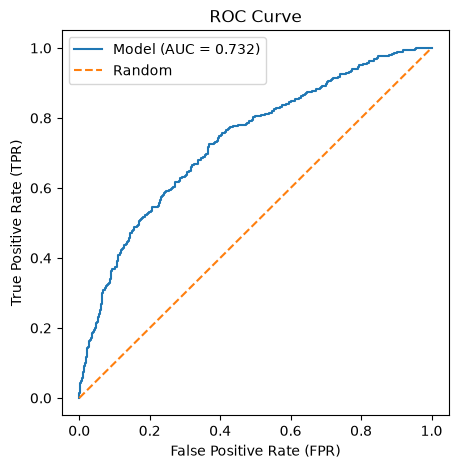

In [56]:
# Predict probabilities on validation data
y_val_pred = model.predict_proba(X_val)[:, 1]

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_val, y_val_pred)

# Calculate ROC-AUC
auc = roc_auc_score(y_val, y_val_pred)
print(f"ROC-AUC: {auc:.4f}")

# Plot ROC curve
plt.figure(figsize=(5, 5))
plt.plot(fpr, tpr, label=f'Model (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random')

plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('ROC Curve')
plt.legend()
plt.show()

In [57]:
# Find the threshold that maximizes
j_scores = tpr - fpr
best_idx = np.argmax(j_scores)

best_threshold = thresholds[best_idx]

print(f"Best threshold: {best_threshold:.3f}")
print(f"TPR: {tpr[best_idx]:.3f}")
print(f"FPR: {fpr[best_idx]:.3f}")

Best threshold: 0.632
TPR: 0.725
FPR: 0.367


In [58]:
def tpr_fpr_dataframe(y_val, y_pred):
    scores = []

    thresholds = np.linspace(0.0, 1.0, 101)

    for t in thresholds:
        actual_positive = (y_val == 1)
        actual_negative = (y_val == 0)

        predict_positive = (y_pred >= t)
        predict_negative = (y_pred < t)

        tp = (predict_positive & actual_positive).sum()
        tn = (predict_negative & actual_negative).sum()

        fp = (predict_positive & actual_negative).sum()
        fn = (predict_negative & actual_positive).sum()

        scores.append((t, tp, fp, fn, tn))

    columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
    df_scores = pd.DataFrame(scores, columns=columns)

    df_scores['tpr'] = df_scores.tp / (df_scores.tp + df_scores.fn)
    df_scores['fpr'] = df_scores.fp / (df_scores.fp + df_scores.tn)

    df_scores['precision'] = (
        df_scores.tp / (df_scores.tp + df_scores.fp)
    ).fillna(0)

    df_scores['recall'] = (
        df_scores.tp / (df_scores.tp + df_scores.fn)
    ).fillna(0)
    
    return df_scores

In [59]:
# Question 3
df_scores = tpr_fpr_dataframe(y_val, y_val_pred)


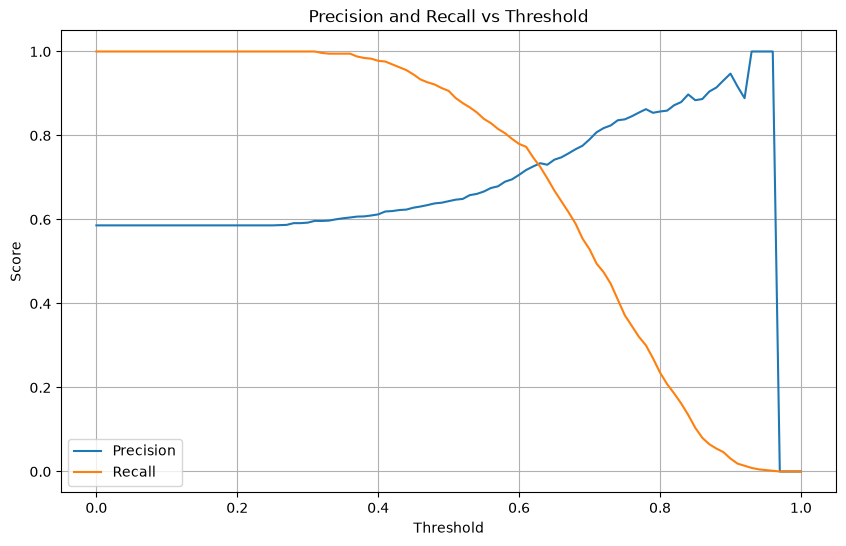

In [60]:
#plot precsion and recall
plt.figure(figsize=(10, 6))

plt.plot(
    df_scores.threshold,
    df_scores.precision,
    label='Precision'
)

plt.plot(
    df_scores.threshold,
    df_scores.recall,
    label='Recall'
)

plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision and Recall vs Threshold')
plt.legend()
plt.grid(True)
plt.show()


In [61]:
df_valid = df_scores[
    ~(
        (df_scores.precision == 0) &
        (df_scores.recall == 0)
    )
].copy()

# get the difference to see where the result is the least
df_valid['diff'] = abs(
    df_valid.precision - df_valid.recall
)

best_idx = df_valid['diff'].idxmin()  #get the index of the lowest difference
best_threshold = df_valid.loc[best_idx, 'threshold']

print("Best threshold:", best_threshold)
print("Precision:", df_valid.loc[best_idx, 'precision'])
print("Recall:", df_valid.loc[best_idx, 'recall'])
print("Absolute difference:", df_valid.loc[best_idx, 'diff'])


Best threshold: 0.63
Precision: 0.7340241796200345
Recall: 0.7252559726962458
Absolute difference: 0.008768206923788768


In [69]:
# Question 4
df_scores["F1-Score"] = (
    2 * (df_scores["precision"].astype(float) * df_scores["recall"].astype(float)) / 
        (df_scores["precision"].astype(float) + df_scores["recall"].astype(float))
    )

best_idx = df_scores["F1-Score"].idxmax()

best_threshold = df_scores.loc[best_idx, "threshold"]
best_f1 = df_scores.loc[best_idx, "F1-Score"]
print(f"best_threshold: {best_threshold:.2f}")
print(f"best_f1: {best_f1}")

best_threshold: 0.41
best_f1: 0.7576158940397352


In [63]:
df_scores

,threshold,tp,fp,fn,tn,tpr,fpr,precision,recall,F1-Score
0,0.00,586,414,0,0,1.000000,1.0,0.586,1.000000,0.586000
1,0.01,586,414,0,0,1.000000,1.0,0.586,1.000000,0.586000
2,0.02,586,414,0,0,1.000000,1.0,0.586,1.000000,0.586000
3,0.03,586,414,0,0,1.000000,1.0,0.586,1.000000,0.586000
4,0.04,586,414,0,0,1.000000,1.0,0.586,1.000000,0.586000
...,...,...,...,...,...,...,...,...,...,...
96,0.96,1,0,585,414,0.001706,0.0,1.000,0.001706,0.001706
97,0.97,0,0,586,414,0.000000,0.0,0.000,0.000000,0.000000
98,0.98,0,0,586,414,0.000000,0.0,0.000,0.000000,0.000000
99,0.99,0,0,586,414,0.000000,0.0,0.000,0.000000,0.000000


In [82]:
# Question 5
n_splits = 5


kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)

scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    train_dict = df_train[categorical_columns + numerical_columns].to_dict(orient='records')
    X_train = dv.fit_transform(train_dict)

    y_train = df_train.converted.values
    y_val = df_val.converted.values 
    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
    model.fit(X_train, y_train)


    val_dict = df_val[categorical_columns + numerical_columns].to_dict(orient='records')

    X_val = dv.transform(val_dict)
    y_val_pred = model.predict_proba(X_val)[:, 1]

    auc = roc_auc_score(y_val, y_val_pred)
    scores.append(auc)

print('%.3f +- %.3f' % (np.mean(scores), np.std(scores)))

0.732 +- 0.007


In [84]:
# Question 6

n_splits = 5

for C in tqdm([0.000001, 0.001, 1]):
    kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)

    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        train_dict = df_train[categorical_columns + numerical_columns].to_dict(orient='records')
        X_train = dv.fit_transform(train_dict)

        y_train = df_train.converted.values
        y_val = df_val.converted.values 
        model = LogisticRegression(solver='liblinear', C=C, max_iter=1000, random_state=42)
        model.fit(X_train, y_train)


        val_dict = df_val[categorical_columns + numerical_columns].to_dict(orient='records')

        X_val = dv.transform(val_dict)
        y_val_pred = model.predict_proba(X_val)[:, 1]

        auc = roc_auc_score(y_val, y_val_pred)
        scores.append(auc)

    print('C=%s %.3f +- %.3f' % (C, np.mean(scores), np.std(scores)))

  0%|          | 0/3 [00:00<?, ?it/s]

C=1e-06 0.617 +- 0.019
C=0.001 0.749 +- 0.010
C=1 0.732 +- 0.007


In [74]:
df_full_train.head(10)

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
1233,paid_ads,technology,student,europe,38757.0,0,0,0.15,0
1056,paid_ads,healthcare,self_employed,north_america,56516.0,2,6,0.59,1
1686,paid_ads,retail,employed,NA,54963.0,1,0,0.13,0
187,social_media,retail,self_employed,NA,26237.0,1,5,0.46,0
3840,organic_search,retail,student,north_america,21992.0,3,6,0.70,1
1525,NA,NA,employed,africa,64976.0,4,4,0.54,0
1272,events,finance,employed,north_america,86236.0,1,5,0.54,1
453,organic_search,retail,employed,europe,42503.0,2,4,0.52,1
1247,referral,manufacturing,unemployed,south_america,21438.0,4,9,0.78,1
3039,paid_ads,technology,student,north_america,56734.0,3,4,0.56,1
